<a href="https://colab.research.google.com/github/mahekparekhbba2025-prog/Wordify/blob/main/mldl_final_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bankruptcy Risk Prediction
### A Complete Machine Learning Pipeline

---

## Problem Statement

Financial distress and corporate bankruptcy have cascading consequences for employees, creditors, investors, and the broader economy. If a company's risk of insolvency can be detected early, stakeholders can act: restructuring debt, adjusting credit lines, or exiting positions before losses materialise.

This notebook builds a supervised classification system that uses a company's financial ratios to predict whether it will go **bankrupt (1)** or **remain solvent (0)**. Five classification algorithms are trained and compared — Logistic Regression, K-Nearest Neighbours, Support Vector Machine, Decision Tree, and Random Forest — covering a wide spectrum of ML approaches from the course syllabus.

---

## Table of Contents

1. [Importing Libraries](#1-importing-libraries)
2. [Loading the Dataset](#2-loading-the-dataset)
3. [Initial Data Overview](#3-initial-data-overview)
4. [Data Quality Checks](#4-data-quality-checks)
5. [Data Cleaning and Preprocessing](#5-data-cleaning-and-preprocessing)
6. [Exploratory Data Analysis](#6-exploratory-data-analysis)
7. [Feature Engineering](#7-feature-engineering)
8. [Feature Selection](#8-feature-selection)
9. [Train-Test Split and Scaling](#9-train-test-split-and-scaling)
10. [Handling Class Imbalance](#10-handling-class-imbalance)
11. [Model 1: Logistic Regression](#11-model-1-logistic-regression)
12. [Model 2: K-Nearest Neighbours](#12-model-2-k-nearest-neighbours)
13. [Model 3: Support Vector Machine](#13-model-3-support-vector-machine)
14. [Model 4: Decision Tree](#14-model-4-decision-tree)
15. [Model 5: Random Forest](#15-model-5-random-forest)
16. [Model 6: Voting Classifier (Ensemble)](#16-model-6-voting-classifier-ensemble)
17. [Model Comparison and Evaluation](#17-model-comparison-and-evaluation)
17. [Feature Importance Analysis](#17-feature-importance-analysis)
18. [ROC Curve Analysis](#18-roc-curve-analysis)
19. [Key Findings and Recommendations](#19-key-findings-and-recommendations)

---


---
## 1. Importing Libraries

In [ ]:
# Core Data and Numerics
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Preprocessing and Model Selection
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    f1_score, precision_score, recall_score,
    roc_curve, roc_auc_score
)

import warnings
warnings.filterwarnings('ignore')

# Global plot style — consistent across all charts
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi']        = 110
plt.rcParams['axes.titleweight']  = 'bold'
plt.rcParams['axes.titlesize']    = 13
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

print("All libraries imported successfully.")


All libraries imported successfully.


---
## 2. Loading the Dataset

In [ ]:
df = pd.read_csv('data.csv')
df.columns = df.columns.str.strip()   # remove leading/trailing spaces from headers

print(f"Dataset loaded.")
print(f"Shape  : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Target : 'Bankrupt?' — Binary (0 = Solvent, 1 = Bankrupt)")


Dataset loaded.
Shape  : 6,819 rows x 96 columns
Target : 'Bankrupt?' — Binary (0 = Solvent, 1 = Bankrupt)


In [ ]:
print("First 5 records:")
df.head()


First 5 records:


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


---
## 3. Initial Data Overview

Before any modifications, examine structure, data types, and statistics.

In [ ]:
print(f"Total columns   : {df.shape[1]}")
print(f"Numeric columns : {df.select_dtypes(include=np.number).shape[1]}")
print(f"Object columns  : {df.select_dtypes(include='object').shape[1]}")
print()
df.info(verbose=False, show_counts=True)


Total columns   : 96
Numeric columns : 96
Object columns  : 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Columns: 96 entries, Bankrupt? to Equity to Liability
dtypes: float64(93), int64(3)
memory usage: 5.0 MB


In [ ]:
print("Descriptive Statistics (transposed):")
df.describe().T.round(4)


Descriptive Statistics (transposed):


,count,mean,std,min,25%,50%,75%,max
Bankrupt?,6819.0,0.0323,0.1767,0.0,0.0000,0.0000,0.0000,1.0
ROA(C) before interest and depreciation before interest,6819.0,0.5052,0.0607,0.0,0.4765,0.5027,0.5356,1.0
ROA(A) before interest and % after tax,6819.0,0.5586,0.0656,0.0,0.5355,0.5598,0.5892,1.0
ROA(B) before interest and depreciation after tax,6819.0,0.5536,0.0616,0.0,0.5273,0.5523,0.5841,1.0
Operating Gross Margin,6819.0,0.6079,0.0169,0.0,0.6004,0.6060,0.6139,1.0
...,...,...,...,...,...,...,...,...
Liability to Equity,6819.0,0.2804,0.0145,0.0,0.2769,0.2788,0.2814,1.0
Degree of Financial Leverage (DFL),6819.0,0.0275,0.0157,0.0,0.0268,0.0268,0.0269,1.0
Interest Coverage Ratio (Interest expense to EBIT),6819.0,0.5654,0.0132,0.0,0.5652,0.5653,0.5657,1.0
Net Income Flag,6819.0,1.0000,0.0000,1.0,1.0000,1.0000,1.0000,1.0


In [ ]:
target_counts = df['Bankrupt?'].value_counts()
target_pct    = df['Bankrupt?'].value_counts(normalize=True) * 100

print("Target Variable Distribution:")
print(f"  Solvent  (0): {target_counts[0]:,} companies  ({target_pct[0]:.2f}%)")
print(f"  Bankrupt (1): {target_counts[1]:,} companies  ({target_pct[1]:.2f}%)")
print()
print(f"Class imbalance ratio: approximately {target_counts[0]//target_counts[1]}:1")
print("Implication: accuracy alone is not a reliable metric here.")


Target Variable Distribution:
  Solvent  (0): 6,599 companies  (96.77%)
  Bankrupt (1): 220 companies  (3.23%)

Class imbalance ratio: approximately 29:1
Implication: accuracy alone is not a reliable metric here.


---
## 4. Data Quality Checks

Systematically inspect for missing values, duplicate records, and column cardinality.

In [ ]:
missing     = df.isnull().sum()
missing_pct = (missing / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Count': missing,
    'Missing %'    : missing_pct.round(2)
}).sort_values('Missing Count', ascending=False)

cols_with_missing = missing_report[missing_report['Missing Count'] > 0]

if len(cols_with_missing) == 0:
    print("No missing values found. The dataset is complete.")
else:
    print(f"{len(cols_with_missing)} columns have missing values:")
    print(cols_with_missing.head(20))


No missing values found. The dataset is complete.


In [ ]:
dupes = df.duplicated().sum()
print(f"Duplicate rows: {dupes}")
if dupes == 0:
    print("No duplicate records found.")
else:
    print(f"{dupes} duplicate rows detected and will be removed.")


Duplicate rows: 0
No duplicate records found.


In [ ]:
cardinality = df.nunique().sort_values()
print("Columns with very few unique values (likely binary indicator columns):")
print(cardinality[cardinality <= 5])


Columns with very few unique values (likely binary indicator columns):
Net Income Flag          1
Bankrupt?                2
Liability-Assets Flag    2
dtype: int64


---
## 5. Data Cleaning and Preprocessing

Remove duplicates and clip extreme outliers using the 3xIQR rule to reduce the influence of erroneous or one-off accounting entries.

In [ ]:
shape_before = df.shape
df.drop_duplicates(inplace=True)
shape_after  = df.shape

print(f"Shape before : {shape_before}")
print(f"Shape after  : {shape_after}")
print(f"Rows removed : {shape_before[0] - shape_after[0]}")


Shape before : (6819, 96)
Shape after  : (6819, 96)
Rows removed : 0


In [ ]:
binary_cols = [col for col in df.columns if df[col].nunique() <= 2 and col != 'Bankrupt?']
print(f"Binary/indicator columns identified: {binary_cols}")


Binary/indicator columns identified: ['Liability-Assets Flag', 'Net Income Flag']


In [ ]:
continuous_cols = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in binary_cols and col != 'Bankrupt?'
]

clipped_cols = 0
for col in continuous_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR    = Q3 - Q1
    lower, upper = Q1 - 3 * IQR, Q3 + 3 * IQR
    n_extreme = ((df[col] < lower) | (df[col] > upper)).sum()
    if n_extreme > 0:
        df[col] = df[col].clip(lower, upper)
        clipped_cols += 1

print(f"Outlier clipping applied to {clipped_cols} continuous columns (3x IQR bounds).")
print("Extreme values in financial ratios often reflect data errors or one-off events.")


Outlier clipping applied to 83 continuous columns (3x IQR bounds).
Extreme values in financial ratios often reflect data errors or one-off events.


---
## 6. Exploratory Data Analysis

EDA answers critical questions: How severe is class imbalance? Which ratios differ between classes? Are features correlated with each other and with the target?

### 6.1 Class Distribution

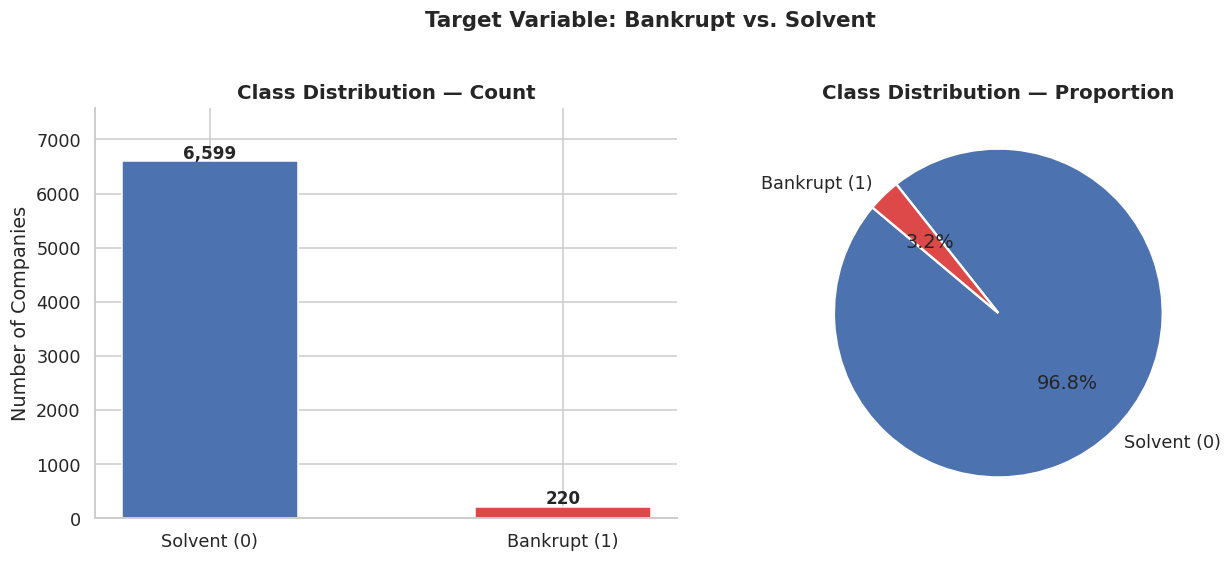


Observation: Only ~3.2% of companies went bankrupt.
A model that always predicts Solvent would score ~96.8% accuracy yet miss all bankruptcies.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
counts = df['Bankrupt?'].value_counts()
labels = ['Solvent (0)', 'Bankrupt (1)']
colors = ['#4C72B0', '#DD4949']

bars = axes[0].bar(labels, counts.values, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{val:,}', ha='center', fontsize=11, fontweight='bold')
axes[0].set_title('Class Distribution — Count')
axes[0].set_ylabel('Number of Companies')
axes[0].set_ylim(0, counts.max() * 1.15)

axes[1].pie(counts.values, labels=labels, autopct='%1.1f%%',
            colors=colors, startangle=140,
            wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Class Distribution — Proportion')

plt.suptitle('Target Variable: Bankrupt vs. Solvent', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print()
print("Observation: Only ~3.2% of companies went bankrupt.")
print("A model that always predicts Solvent would score ~96.8% accuracy yet miss all bankruptcies.")


### 6.2 Feature Distributions: Bankrupt vs. Solvent

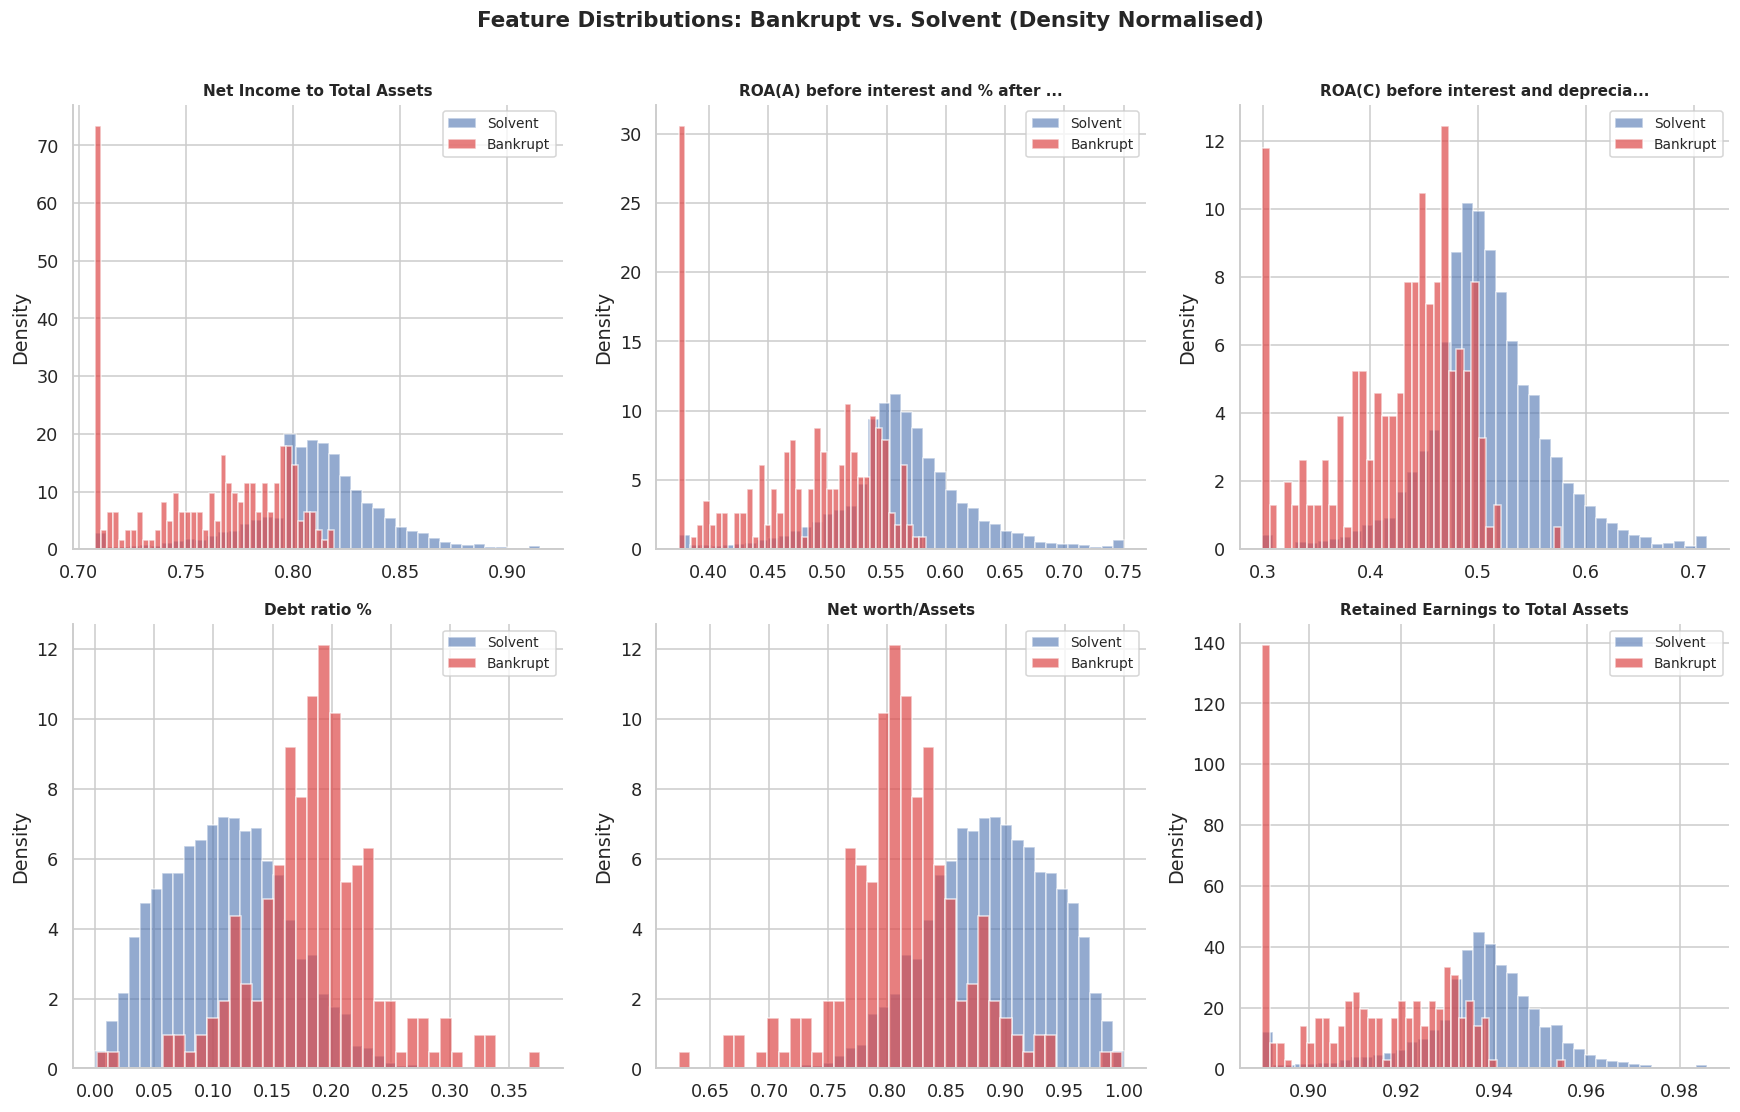

In [ ]:
key_features = [
    'Net Income to Total Assets',
    'ROA(A) before interest and % after tax',
    'ROA(C) before interest and depreciation before interest',
    'Debt ratio %',
    'Net worth/Assets',
    'Retained Earnings to Total Assets'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(key_features):
    solvent_vals  = df[df['Bankrupt?'] == 0][col]
    bankrupt_vals = df[df['Bankrupt?'] == 1][col]
    axes[i].hist(solvent_vals,  bins=40, alpha=0.6, color='#4C72B0', label='Solvent',  density=True)
    axes[i].hist(bankrupt_vals, bins=40, alpha=0.7, color='#DD4949', label='Bankrupt', density=True)
    short = col[:35] + '...' if len(col) > 35 else col
    axes[i].set_title(short, fontsize=10)
    axes[i].set_ylabel('Density')
    axes[i].legend(fontsize=9)

plt.suptitle('Feature Distributions: Bankrupt vs. Solvent (Density Normalised)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### 6.3 Boxplots by Bankruptcy Status

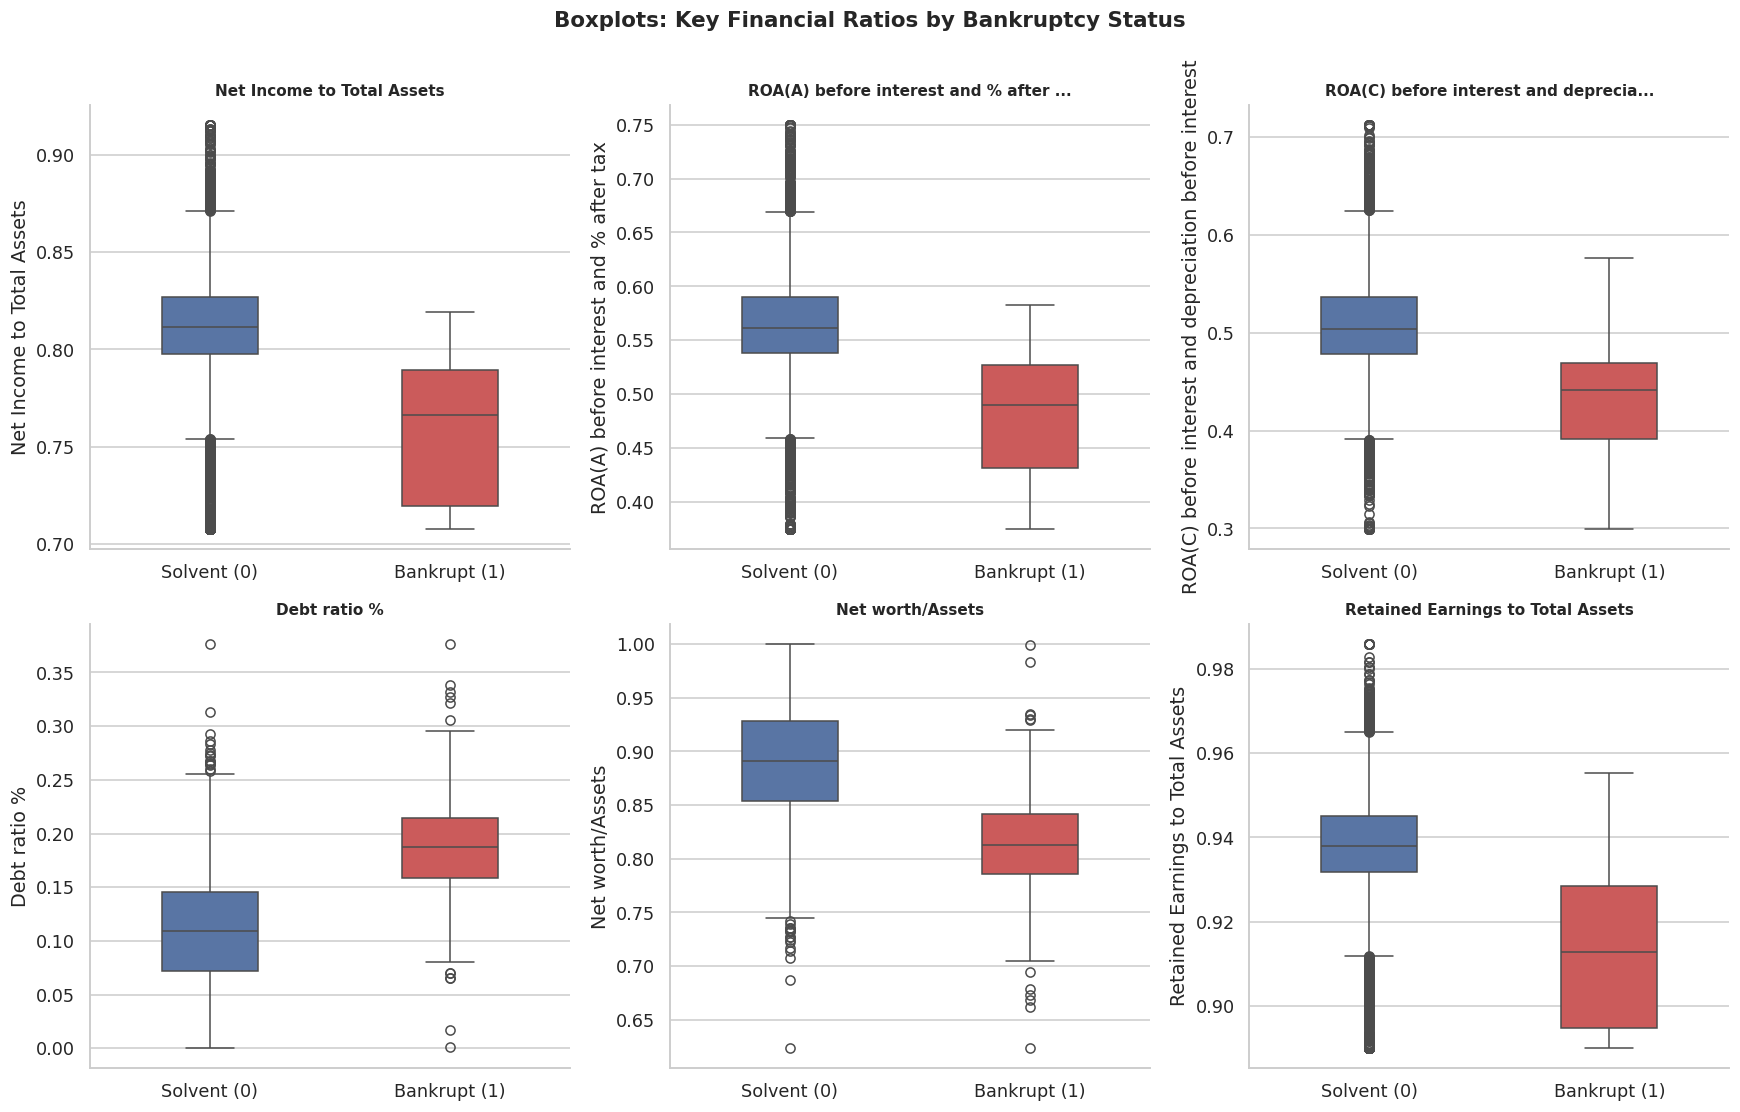


Observation: Bankrupt companies show lower profitability ratios and higher debt ratios.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()
palette = {'0': '#4C72B0', '1': '#DD4949'}

for i, col in enumerate(key_features):
    sns.boxplot(data=df, x='Bankrupt?', y=col, palette=palette, ax=axes[i], width=0.4)
    axes[i].set_xticklabels(['Solvent (0)', 'Bankrupt (1)'])
    short = col[:35] + '...' if len(col) > 35 else col
    axes[i].set_title(short, fontsize=10)
    axes[i].set_xlabel('')

plt.suptitle('Boxplots: Key Financial Ratios by Bankruptcy Status',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print()
print("Observation: Bankrupt companies show lower profitability ratios and higher debt ratios.")

### 6.4 Correlation Heatmap — Top 15 Features

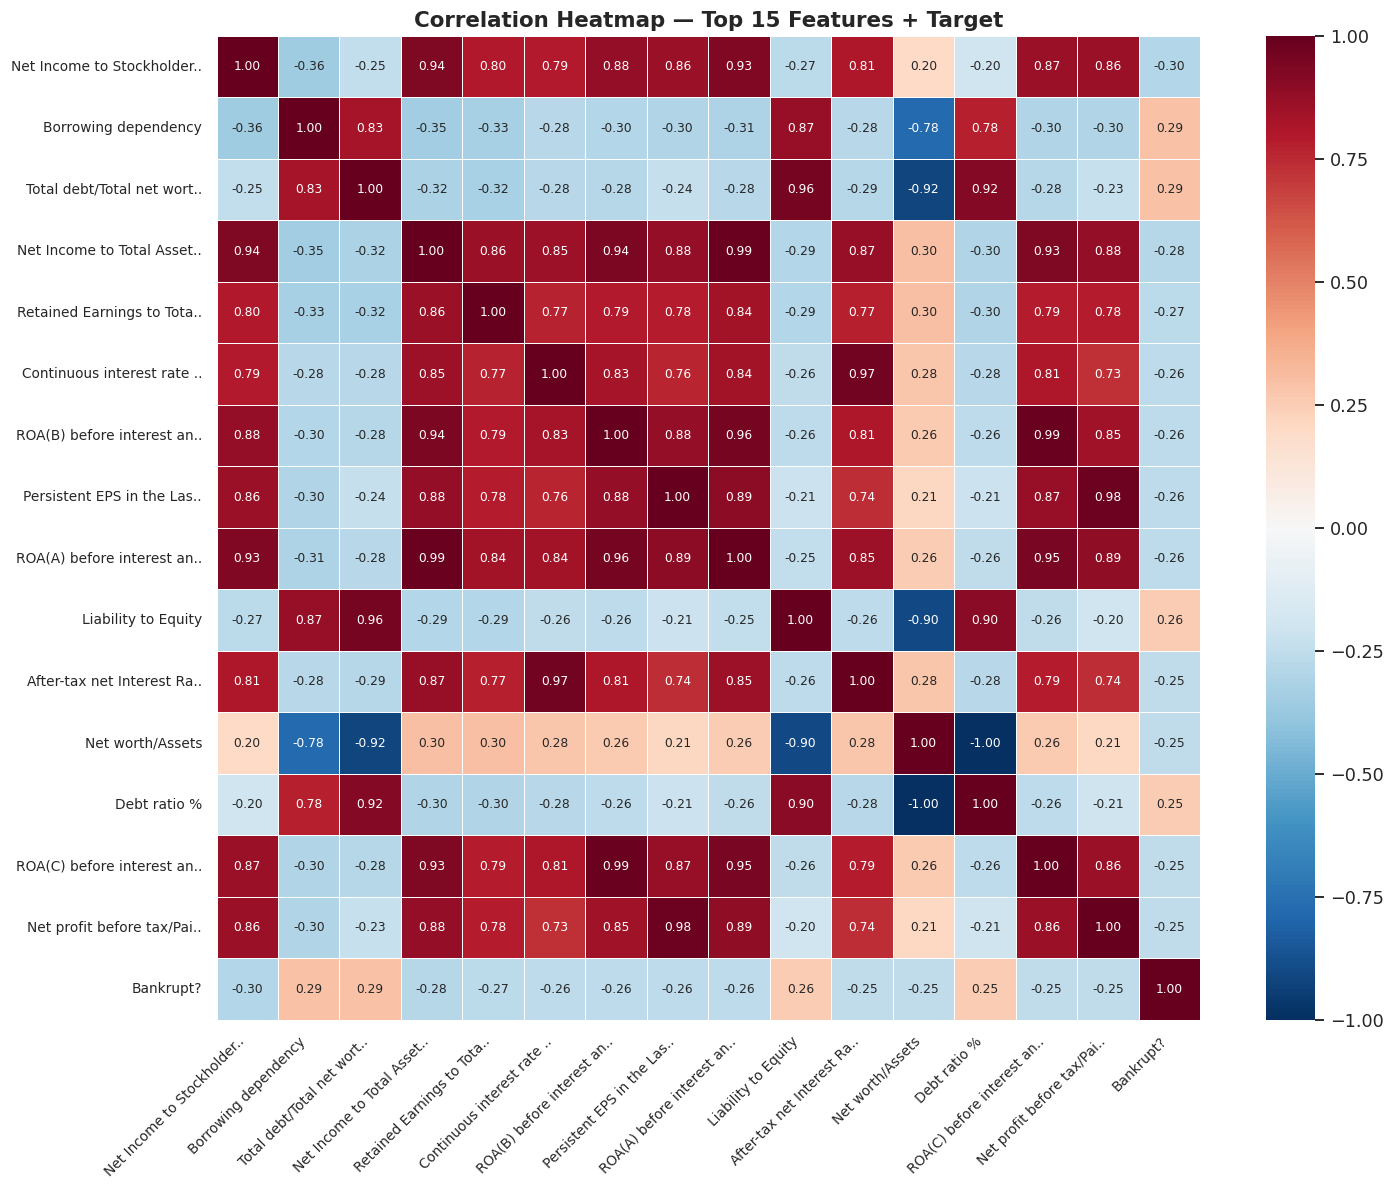

In [ ]:
all_feats   = [col for col in df.columns if col != 'Bankrupt?']
target_corr = df[all_feats + ['Bankrupt?']].corr()['Bankrupt?'].drop('Bankrupt?')
top15       = target_corr.abs().sort_values(ascending=False).head(15).index.tolist()

short_labels = {col: col[:25] + '..' if len(col) > 25 else col for col in top15}
subset       = df[top15 + ['Bankrupt?']].rename(columns=short_labels)
corr_matrix  = subset.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, linewidths=0.4, square=True, annot_kws={'size': 8})
plt.title('Correlation Heatmap — Top 15 Features + Target', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()


### 6.5 Feature-Target Correlation Bar Chart

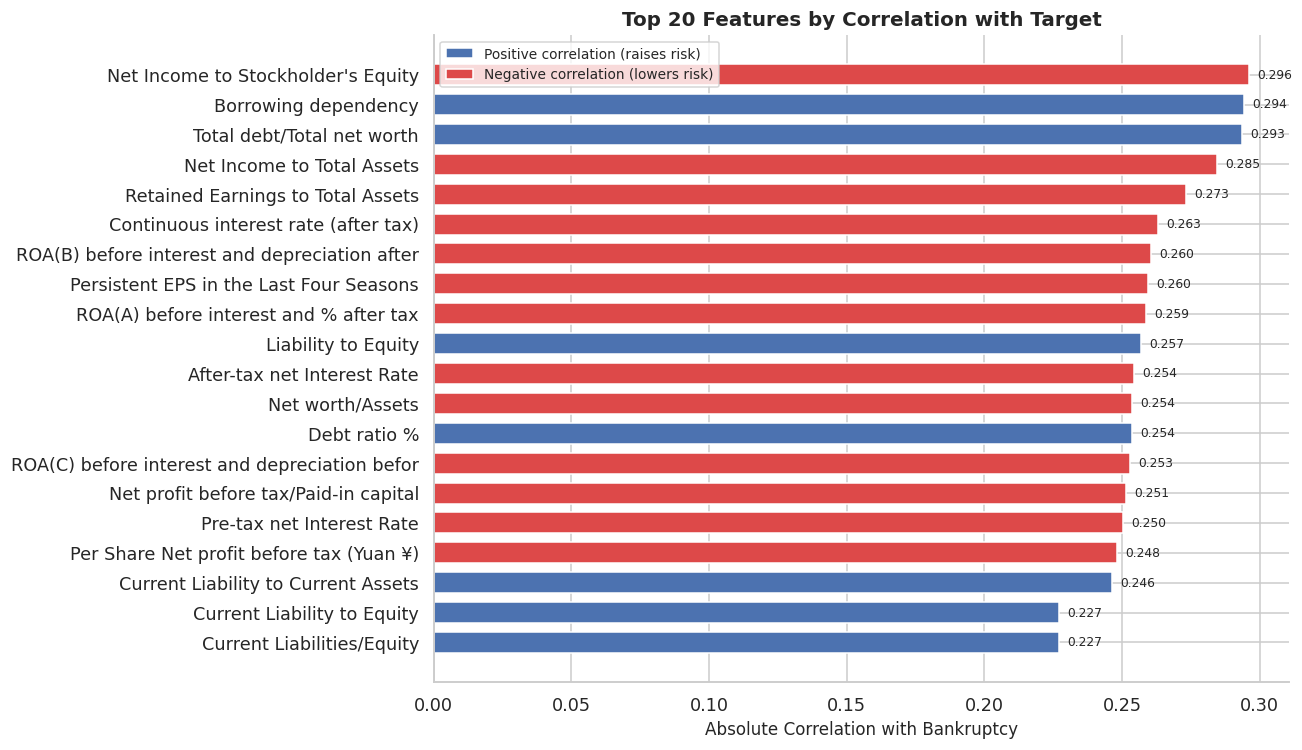

In [ ]:
top20_corr = target_corr.abs().sort_values(ascending=False).head(20)
direction  = target_corr[top20_corr.index]
bar_colors = ['#4C72B0' if v > 0 else '#DD4949' for v in direction.values]

plt.figure(figsize=(12, 7))
bars = plt.barh([col[:45] for col in top20_corr.index],
                top20_corr.values, color=bar_colors, edgecolor='white', height=0.7)
for bar, val in zip(bars, top20_corr.values):
    plt.text(val + 0.003, bar.get_y() + bar.get_height()/2,
             f'{val:.3f}', va='center', fontsize=8)
plt.xlabel('Absolute Correlation with Bankruptcy', fontsize=11)
plt.title('Top 20 Features by Correlation with Target', fontsize=13, fontweight='bold')
plt.gca().invert_yaxis()
legend_els = [Patch(facecolor='#4C72B0', label='Positive correlation (raises risk)'),
              Patch(facecolor='#DD4949', label='Negative correlation (lowers risk)')]
plt.legend(handles=legend_els, fontsize=9)
plt.tight_layout()
plt.show()


---
## 7. Feature Engineering

Three composite indicators are constructed from domain knowledge about financial health.

In [ ]:
# Profitability Score — average of three ROA variants
roa_cols = [
    'ROA(C) before interest and depreciation before interest',
    'ROA(A) before interest and % after tax',
    'ROA(B) before interest and depreciation after tax'
]
df['Profitability_Score'] = df[roa_cols].mean(axis=1)

# Leverage Index — debt burden relative to equity base
if 'Net worth/Assets' in df.columns and 'Debt ratio %' in df.columns:
    df['Leverage_Index'] = df['Debt ratio %'] / (df['Net worth/Assets'].replace(0, np.nan) + 1e-6)
    df['Leverage_Index'] = df['Leverage_Index'].fillna(df['Leverage_Index'].median())

# Liquidity-Solvency Composite
if 'Current Ratio' in df.columns and 'Retained Earnings to Total Assets' in df.columns:
    df['Liquidity_Solvency'] = (df['Current Ratio'] * 0.5 +
                                 df['Retained Earnings to Total Assets'] * 0.5)

print("Engineered features created:")
print("  1. Profitability_Score  — Average ROA across three measurement bases")
print("  2. Leverage_Index       — Debt ratio relative to equity base")
print("  3. Liquidity_Solvency   — Composite short-term and long-term financial health")
print(f"\nDataset now has {df.shape[1]} columns.")


Engineered features created:
  1. Profitability_Score  — Average ROA across three measurement bases
  2. Leverage_Index       — Debt ratio relative to equity base
  3. Liquidity_Solvency   — Composite short-term and long-term financial health

Dataset now has 99 columns.


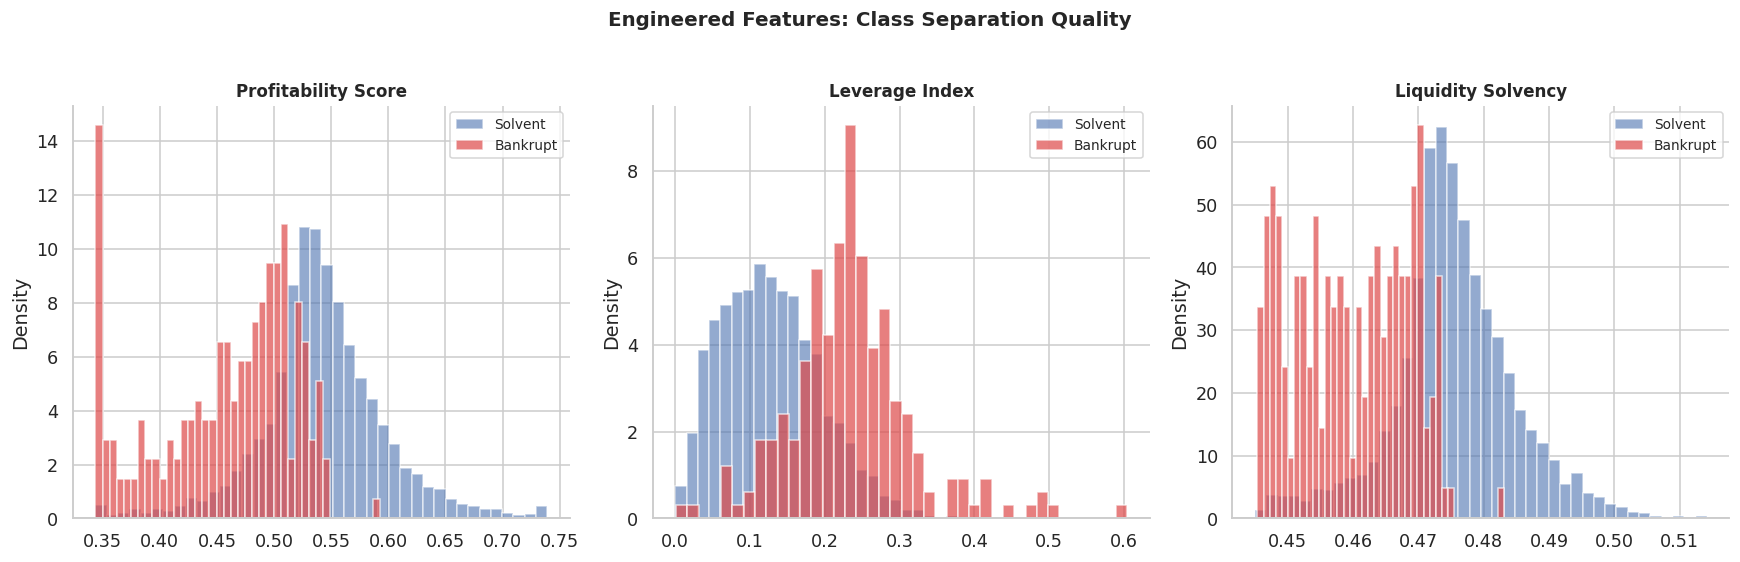

In [ ]:
eng_features = ['Profitability_Score', 'Leverage_Index', 'Liquidity_Solvency']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, col in enumerate(eng_features):
    solvent_vals  = df[df['Bankrupt?'] == 0][col]
    bankrupt_vals = df[df['Bankrupt?'] == 1][col]
    axes[i].hist(solvent_vals,  bins=40, alpha=0.6, color='#4C72B0', label='Solvent',  density=True)
    axes[i].hist(bankrupt_vals, bins=40, alpha=0.7, color='#DD4949', label='Bankrupt', density=True)
    axes[i].set_title(col.replace('_', ' '), fontsize=11)
    axes[i].set_ylabel('Density')
    axes[i].legend(fontsize=9)

plt.suptitle('Engineered Features: Class Separation Quality', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 8. Feature Selection

With 95+ columns, selecting the most informative features reduces noise and computational cost. The top 20 features by absolute correlation with the target are retained.

In [ ]:
feature_cols     = [col for col in df.columns if col != 'Bankrupt?']
target_corr_full = df[feature_cols + ['Bankrupt?']].corr()['Bankrupt?'].drop('Bankrupt?')
target_corr_abs  = target_corr_full.abs().sort_values(ascending=False)

N_FEATURES        = 20
selected_features = target_corr_abs.head(N_FEATURES).index.tolist()

print(f"Top {N_FEATURES} features selected by absolute correlation with target:")
print()
for rank, (feat, val) in enumerate(target_corr_abs.head(N_FEATURES).items(), 1):
    direction = '+' if target_corr_full[feat] > 0 else '-'
    print(f"  {rank:2d}. [{direction}] {feat[:55]:<55}  |r| = {val:.4f}")


Top 20 features selected by absolute correlation with target:

   1. [-] Net Income to Stockholder's Equity                       |r| = 0.2960
   2. [+] Borrowing dependency                                     |r| = 0.2943
   3. [+] Total debt/Total net worth                               |r| = 0.2934
   4. [-] Net Income to Total Assets                               |r| = 0.2846
   5. [-] Liquidity_Solvency                                       |r| = 0.2809
   6. [-] Retained Earnings to Total Assets                        |r| = 0.2732
   7. [+] Leverage_Index                                           |r| = 0.2703
   8. [-] Continuous interest rate (after tax)                     |r| = 0.2631
   9. [-] Profitability_Score                                      |r| = 0.2605
  10. [-] ROA(B) before interest and depreciation after tax        |r| = 0.2604
  11. [-] Persistent EPS in the Last Four Seasons                  |r| = 0.2596
  12. [-] ROA(A) before interest and % after tax         

---
## 9. Train-Test Split and Scaling

A stratified 80/20 split preserves class proportions. StandardScaler is fit **only** on training data to prevent data leakage into the test set.

In [ ]:
X = df[selected_features].values
y = df['Bankrupt?'].values

print(f"Feature matrix : {X.shape}")
print(f"Target vector  : {y.shape}")
print()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set   : {X_train.shape[0]:,} samples  |  Bankrupt: {y_train.sum():,}  ({y_train.mean()*100:.2f}%)")
print(f"Test set       : {X_test.shape[0]:,} samples  |  Bankrupt: {y_test.sum():,}  ({y_test.mean()*100:.2f}%)")
print()

scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)   # fit only on train — no leakage

print("StandardScaler applied (fit on training data only).")


Feature matrix : (6819, 20)
Target vector  : (6819,)

Training set   : 5,455 samples  |  Bankrupt: 176  (3.23%)
Test set       : 1,364 samples  |  Bankrupt: 44  (3.23%)

StandardScaler applied (fit on training data only).


---
## 10. Handling Class Imbalance

Two complementary strategies are used:
- **`class_weight='balanced'`** in Logistic Regression, SVC, and Random Forest: upweights minority class errors in the loss function
- **Random oversampling** for KNN and Decision Tree: duplicates minority samples to create a balanced training set

In [ ]:
X_train_majority = X_train_sc[y_train == 0]
y_train_majority = y_train[y_train == 0]
X_train_minority = X_train_sc[y_train == 1]
y_train_minority = y_train[y_train == 1]

print(f"Before oversampling — Majority: {len(y_train_majority):,} | Minority: {len(y_train_minority):,}")

X_minority_up, y_minority_up = resample(
    X_train_minority, y_train_minority,
    replace=True, n_samples=len(y_train_majority), random_state=42
)

X_train_bal = np.vstack([X_train_majority, X_minority_up])
y_train_bal = np.hstack([y_train_majority, y_minority_up])

print(f"After oversampling  — Majority: {(y_train_bal==0).sum():,} | Minority: {(y_train_bal==1).sum():,}")
print(f"Total balanced training size: {len(y_train_bal):,}")


Before oversampling — Majority: 5,279 | Minority: 176
After oversampling  — Majority: 5,279 | Minority: 5,279
Total balanced training size: 10,558


---
## 11. Model 1: Logistic Regression

Logistic Regression is the standard baseline for binary classification: interpretable, fast, and producing well-calibrated probability estimates. Using `class_weight='balanced'` to counteract the imbalance.

In [ ]:
results = {}

def train_and_evaluate(name, model, X_tr, y_tr, X_te, y_te):
    """Train a model, compute all metrics, and store results."""
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    if hasattr(model, 'predict_proba'):
        y_scores = model.predict_proba(X_te)[:, 1]
    elif hasattr(model, 'decision_function'):
        y_scores = model.decision_function(X_te)
    else:
        y_scores = y_pred.astype(float)

    results[name] = {
        'model'    : model,
        'y_pred'   : y_pred,
        'y_scores' : y_scores,
        'Accuracy' : accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred, zero_division=0),
        'Recall'   : recall_score(y_te, y_pred, zero_division=0),
        'F1'       : f1_score(y_te, y_pred, zero_division=0),
        'AUC-ROC'  : roc_auc_score(y_te, y_scores)
    }
    r = results[name]
    print(f"{name:<25}  Acc={r['Accuracy']:.4f}  Prec={r['Precision']:.4f}  "
          f"Rec={r['Recall']:.4f}  F1={r['F1']:.4f}  AUC={r['AUC-ROC']:.4f}")

print(f"{'Model':<25}  {'Accuracy':>8}  {'Precision':>9}  {'Recall':>6}  {'F1':>6}  {'AUC-ROC':>7}")
print('-' * 75)


Model                      Accuracy  Precision  Recall      F1  AUC-ROC
---------------------------------------------------------------------------


In [ ]:
lr = LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42, C=1.0)
train_and_evaluate('Logistic Regression', lr, X_train_sc, y_train, X_test_sc, y_test)

print("\nClassification Report:")
print(classification_report(y_test, results['Logistic Regression']['y_pred'],
                             target_names=['Solvent', 'Bankrupt']))


Logistic Regression        Acc=0.8768  Prec=0.1900  Rec=0.8636  F1=0.3115  AUC=0.9379

Classification Report:
              precision    recall  f1-score   support

     Solvent       0.99      0.88      0.93      1320
    Bankrupt       0.19      0.86      0.31        44

    accuracy                           0.88      1364
   macro avg       0.59      0.87      0.62      1364
weighted avg       0.97      0.88      0.91      1364



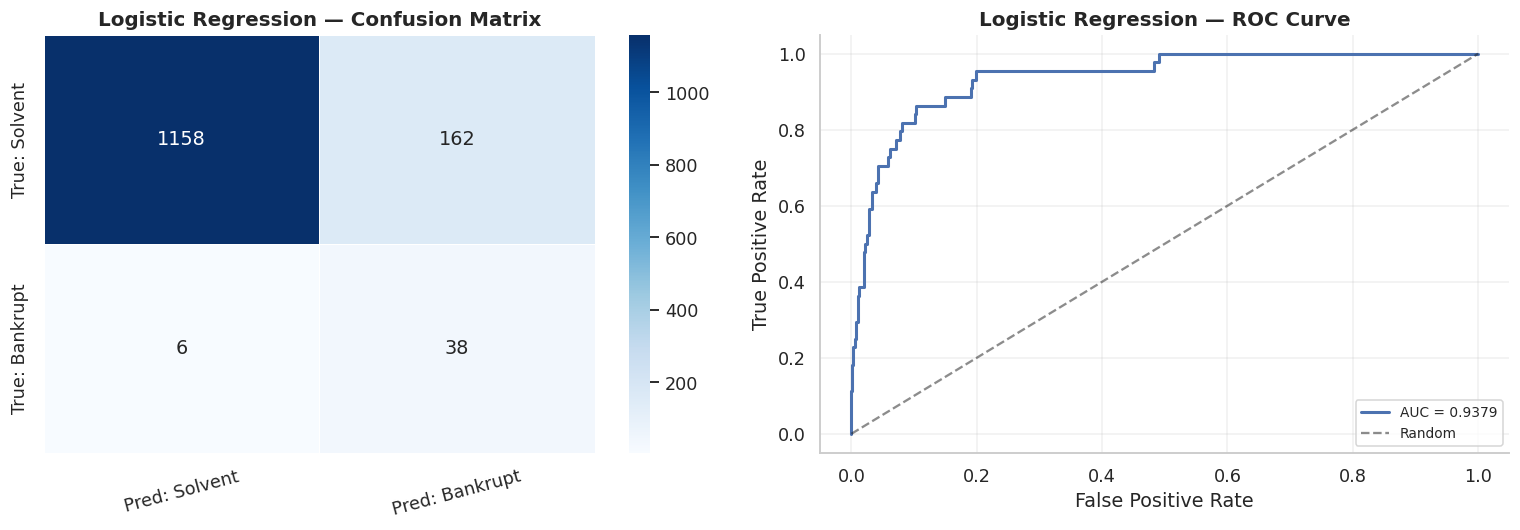

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, results['Logistic Regression']['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred: Solvent', 'Pred: Bankrupt'],
            yticklabels=['True: Solvent', 'True: Bankrupt'],
            linewidths=0.5, cbar=True)
axes[0].set_title('Logistic Regression — Confusion Matrix')
axes[0].tick_params(axis='x', rotation=15)

fpr, tpr, _ = roc_curve(y_test, results['Logistic Regression']['y_scores'])
axes[1].plot(fpr, tpr, color='#4C72B0', lw=2,
             label=f'AUC = {results["Logistic Regression"]["AUC-ROC"]:.4f}')
axes[1].plot([0,1],[0,1], 'k--', lw=1.5, alpha=0.5, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Logistic Regression — ROC Curve')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


---
## 12. Model 2: K-Nearest Neighbours (KNN)

KNN classifies a sample by majority vote (distance-weighted) among its k nearest training examples. It is sensitive to scale and class imbalance, so the oversampled balanced training set is used. We first sweep K values to identify the best k by F1 score.

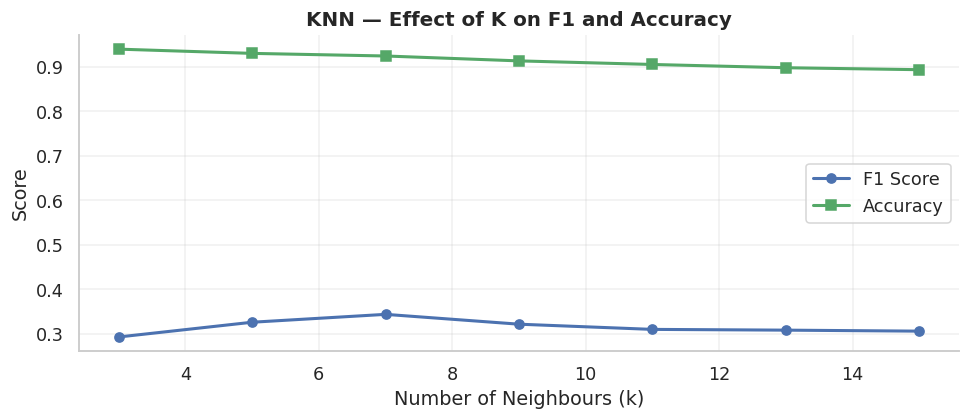

Best k by F1 score: 7


In [ ]:
k_range      = range(3, 16, 2)
k_f1_scores  = []
k_acc_scores = []

for k in k_range:
    knn_k = KNeighborsClassifier(n_neighbors=k, metric='minkowski', weights='distance')
    knn_k.fit(X_train_bal, y_train_bal)
    y_pred_k = knn_k.predict(X_test_sc)
    k_f1_scores.append(f1_score(y_test, y_pred_k, zero_division=0))
    k_acc_scores.append(accuracy_score(y_test, y_pred_k))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(list(k_range), k_f1_scores,  marker='o', label='F1 Score', color='#4C72B0', lw=2)
ax.plot(list(k_range), k_acc_scores, marker='s', label='Accuracy', color='#55A868', lw=2)
ax.set_xlabel('Number of Neighbours (k)')
ax.set_ylabel('Score')
ax.set_title('KNN — Effect of K on F1 and Accuracy')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_k = list(k_range)[k_f1_scores.index(max(k_f1_scores))]
print(f"Best k by F1 score: {best_k}")


In [ ]:
knn = KNeighborsClassifier(n_neighbors=best_k, metric='minkowski', weights='distance')
train_and_evaluate('KNN', knn, X_train_bal, y_train_bal, X_test_sc, y_test)

print("\nClassification Report:")
print(classification_report(y_test, results['KNN']['y_pred'],
                             target_names=['Solvent', 'Bankrupt']))


KNN                        Acc=0.9245  Prec=0.2389  Rec=0.6136  F1=0.3439  AUC=0.8196

Classification Report:
              precision    recall  f1-score   support

     Solvent       0.99      0.93      0.96      1320
    Bankrupt       0.24      0.61      0.34        44

    accuracy                           0.92      1364
   macro avg       0.61      0.77      0.65      1364
weighted avg       0.96      0.92      0.94      1364



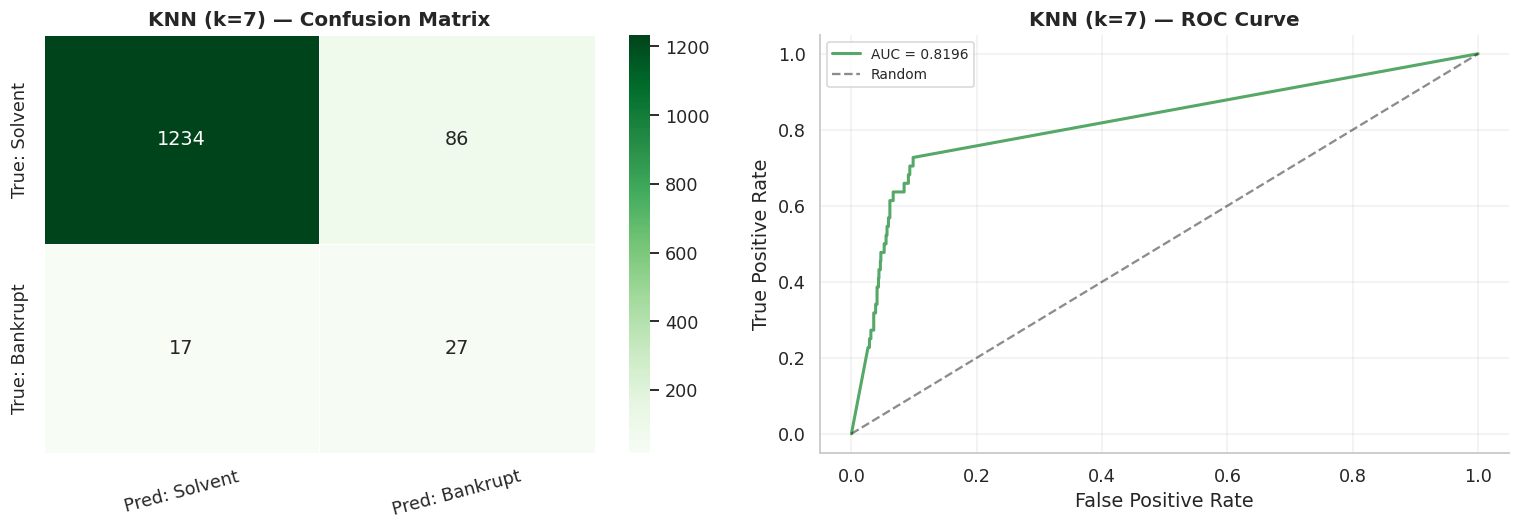

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, results['KNN']['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Pred: Solvent', 'Pred: Bankrupt'],
            yticklabels=['True: Solvent', 'True: Bankrupt'],
            linewidths=0.5, cbar=True)
axes[0].set_title(f'KNN (k={best_k}) — Confusion Matrix')
axes[0].tick_params(axis='x', rotation=15)

fpr, tpr, _ = roc_curve(y_test, results['KNN']['y_scores'])
axes[1].plot(fpr, tpr, color='#55A868', lw=2,
             label=f'AUC = {results["KNN"]["AUC-ROC"]:.4f}')
axes[1].plot([0,1],[0,1], 'k--', lw=1.5, alpha=0.5, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title(f'KNN (k={best_k}) — ROC Curve')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


---
## 13. Model 3: Support Vector Machine (SVM)

SVM finds the maximum-margin hyperplane separating the two classes. We compare two variants:
- **Linear SVC** — fast, suitable for linearly separable data
- **SVC with RBF kernel** — more flexible, captures non-linear decision boundaries

`class_weight='balanced'` penalises minority class errors more heavily.

In [ ]:
svc_linear = LinearSVC(C=1.0, class_weight='balanced', random_state=42, max_iter=5000)
train_and_evaluate('SVM (Linear)', svc_linear, X_train_sc, y_train, X_test_sc, y_test)

svc_rbf = SVC(kernel='rbf', C=1.0, gamma='scale',
              class_weight='balanced', random_state=42, probability=True)
train_and_evaluate('SVM (RBF)', svc_rbf, X_train_sc, y_train, X_test_sc, y_test)

print("\nClassification Report — SVM (RBF):")
print(classification_report(y_test, results['SVM (RBF)']['y_pred'],
                             target_names=['Solvent', 'Bankrupt']))


SVM (Linear)               Acc=0.8724  Prec=0.1845  Rec=0.8636  F1=0.3040  AUC=0.9354
SVM (RBF)                  Acc=0.8761  Prec=0.1827  Rec=0.8182  F1=0.2988  AUC=0.9176

Classification Report — SVM (RBF):
              precision    recall  f1-score   support

     Solvent       0.99      0.88      0.93      1320
    Bankrupt       0.18      0.82      0.30        44

    accuracy                           0.88      1364
   macro avg       0.59      0.85      0.62      1364
weighted avg       0.97      0.88      0.91      1364



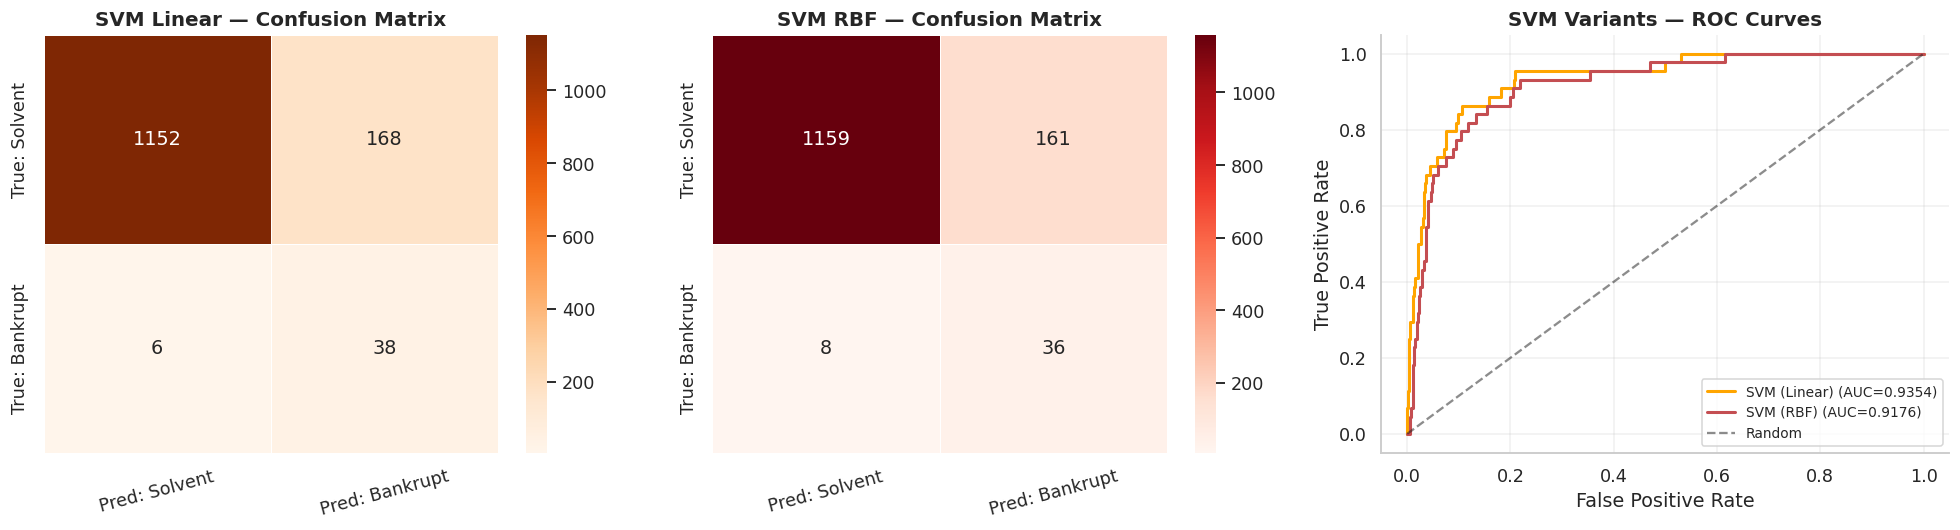

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_lin = confusion_matrix(y_test, results['SVM (Linear)']['y_pred'])
sns.heatmap(cm_lin, annot=True, fmt='d', cmap='Oranges', ax=axes[0],
            xticklabels=['Pred: Solvent', 'Pred: Bankrupt'],
            yticklabels=['True: Solvent', 'True: Bankrupt'], linewidths=0.5)
axes[0].set_title('SVM Linear — Confusion Matrix')
axes[0].tick_params(axis='x', rotation=15)

cm_rbf = confusion_matrix(y_test, results['SVM (RBF)']['y_pred'])
sns.heatmap(cm_rbf, annot=True, fmt='d', cmap='Reds', ax=axes[1],
            xticklabels=['Pred: Solvent', 'Pred: Bankrupt'],
            yticklabels=['True: Solvent', 'True: Bankrupt'], linewidths=0.5)
axes[1].set_title('SVM RBF — Confusion Matrix')
axes[1].tick_params(axis='x', rotation=15)

for name, color in [('SVM (Linear)', '#FFA500'), ('SVM (RBF)', '#C44E52')]:
    fpr, tpr, _ = roc_curve(y_test, results[name]['y_scores'])
    axes[2].plot(fpr, tpr, color=color, lw=2,
                 label=f'{name} (AUC={results[name]["AUC-ROC"]:.4f})')
axes[2].plot([0,1],[0,1], 'k--', lw=1.5, alpha=0.5, label='Random')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].set_title('SVM Variants — ROC Curves')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.show()


---
## 14. Model 4: Decision Tree

Decision Trees produce interpretable rule-based classifiers. Each internal node applies a threshold on a financial ratio. Limiting tree depth (`max_depth=8`) prevents overfitting. The rules are directly auditable — an advantage in regulated financial contexts.

In [ ]:
dt = DecisionTreeClassifier(max_depth=8, class_weight='balanced',
                             random_state=42, min_samples_leaf=5)
train_and_evaluate('Decision Tree', dt, X_train_sc, y_train, X_test_sc, y_test)

print("\nClassification Report:")
print(classification_report(y_test, results['Decision Tree']['y_pred'],
                             target_names=['Solvent', 'Bankrupt']))


Decision Tree              Acc=0.9076  Prec=0.2029  Rec=0.6364  F1=0.3077  AUC=0.7832

Classification Report:
              precision    recall  f1-score   support

     Solvent       0.99      0.92      0.95      1320
    Bankrupt       0.20      0.64      0.31        44

    accuracy                           0.91      1364
   macro avg       0.59      0.78      0.63      1364
weighted avg       0.96      0.91      0.93      1364



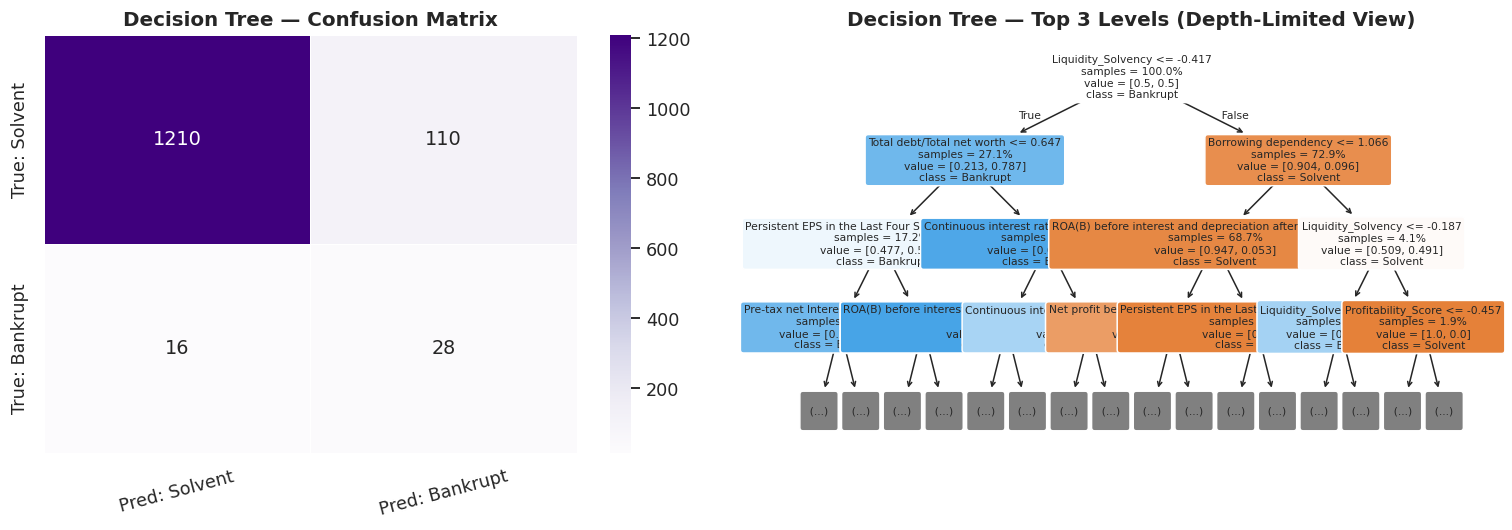

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, results['Decision Tree']['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=['Pred: Solvent', 'Pred: Bankrupt'],
            yticklabels=['True: Solvent', 'True: Bankrupt'], linewidths=0.5)
axes[0].set_title('Decision Tree — Confusion Matrix')
axes[0].tick_params(axis='x', rotation=15)

plt.sca(axes[1])
plot_tree(dt, feature_names=selected_features,
          class_names=['Solvent', 'Bankrupt'],
          max_depth=3, filled=True, rounded=True, fontsize=7,
          impurity=False, proportion=True)
axes[1].set_title('Decision Tree — Top 3 Levels (Depth-Limited View)')

plt.tight_layout()
plt.show()


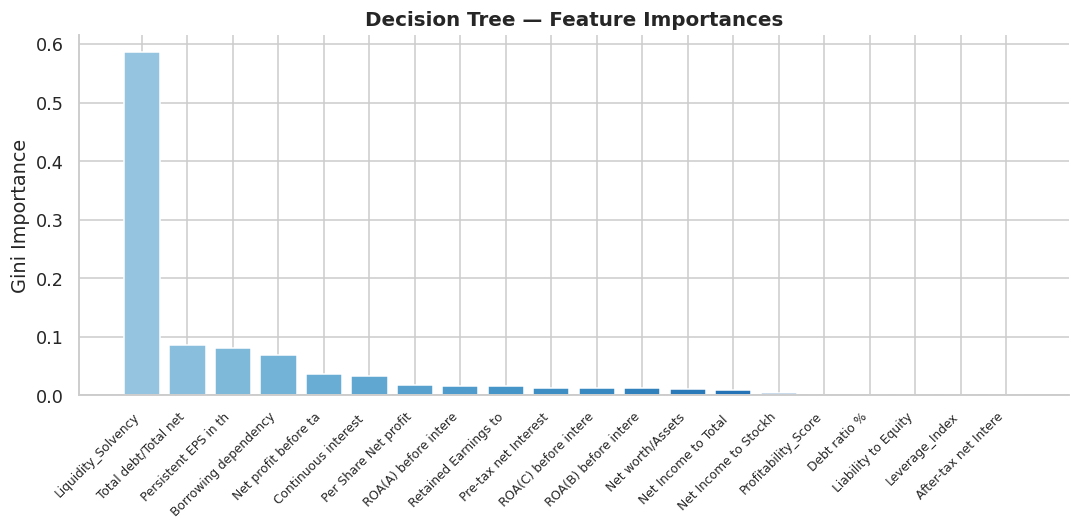

In [ ]:
# Decision Tree feature importances
dt_importances = pd.Series(dt.feature_importances_, index=selected_features).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
bars = plt.bar(range(len(dt_importances)), dt_importances.values,
               color=plt.cm.Blues(np.linspace(0.4, 0.9, len(dt_importances))),
               edgecolor='white')
plt.xticks(range(len(dt_importances)),
           [col[:20] for col in dt_importances.index], rotation=45, ha='right', fontsize=8)
plt.ylabel('Gini Importance')
plt.title('Decision Tree — Feature Importances', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
## 15. Model 5: Random Forest

Random Forest is an ensemble of decision trees trained on random data subsets (bagging) with random feature subsets at each split. The final prediction is a majority vote. This variance-reduction strategy typically outperforms any single tree and provides reliable built-in feature importances.

In [ ]:
rf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced',
                             random_state=42, n_jobs=-1, min_samples_leaf=3)
train_and_evaluate('Random Forest', rf, X_train_sc, y_train, X_test_sc, y_test)

print("\nClassification Report:")
print(classification_report(y_test, results['Random Forest']['y_pred'],
                             target_names=['Solvent', 'Bankrupt']))


Random Forest              Acc=0.9494  Prec=0.3494  Rec=0.6591  F1=0.4567  AUC=0.9315

Classification Report:
              precision    recall  f1-score   support

     Solvent       0.99      0.96      0.97      1320
    Bankrupt       0.35      0.66      0.46        44

    accuracy                           0.95      1364
   macro avg       0.67      0.81      0.72      1364
weighted avg       0.97      0.95      0.96      1364



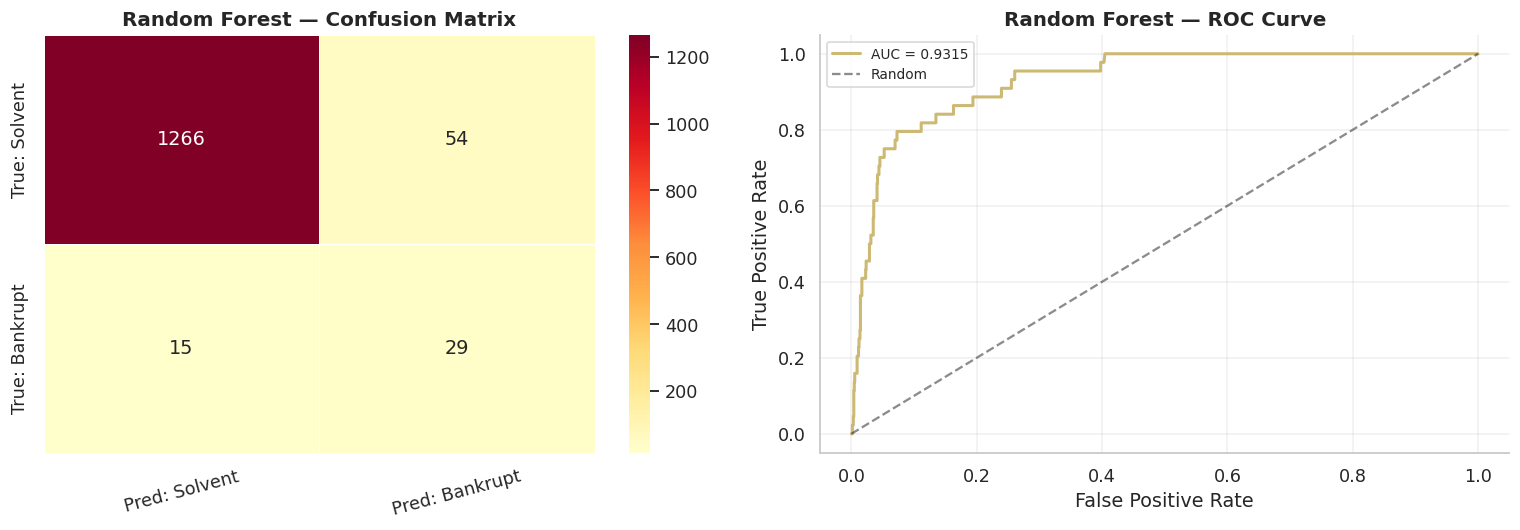

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, results['Random Forest']['y_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd', ax=axes[0],
            xticklabels=['Pred: Solvent', 'Pred: Bankrupt'],
            yticklabels=['True: Solvent', 'True: Bankrupt'], linewidths=0.5)
axes[0].set_title('Random Forest — Confusion Matrix')
axes[0].tick_params(axis='x', rotation=15)

fpr, tpr, _ = roc_curve(y_test, results['Random Forest']['y_scores'])
axes[1].plot(fpr, tpr, color='#CCB974', lw=2,
             label=f'AUC = {results["Random Forest"]["AUC-ROC"]:.4f}')
axes[1].plot([0,1],[0,1], 'k--', lw=1.5, alpha=0.5, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Random Forest — ROC Curve')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


---
## 16. Model 6: Voting Classifier (Ensemble)

A **Voting Classifier** combines the predictions of multiple base learners and outputs the class that receives the majority vote (hard voting) or the highest average predicted probability (soft voting). Here, the three strongest individual models — Logistic Regression, SVM (RBF), and Random Forest — are combined. Soft voting is used so that each model's predicted probability is averaged rather than just its hard class label, giving a more calibrated ensemble decision.

This approach leverages the complementary strengths of a linear model, a kernel-based model, and a tree ensemble, which often yields better generalisation than any single model alone.

> **Note:** `VotingClassifier` is imported from `sklearn.ensemble`. The import line below adds it alongside the existing imports.

In [ ]:
from sklearn.ensemble import VotingClassifier

# --- Base estimators (re-instantiated so state is clean) ---
lr_vc  = LogisticRegression(C=0.1, class_weight='balanced',
                             solver='lbfgs', max_iter=1000, random_state=42)

svm_vc = SVC(kernel='rbf', C=1.0, gamma='scale',
             class_weight='balanced', probability=True, random_state=42)

rf_vc  = RandomForestClassifier(n_estimators=200, max_depth=10,
                                 class_weight='balanced', random_state=42,
                                 n_jobs=-1, min_samples_leaf=3)

# --- Soft Voting Classifier ---
voting_clf = VotingClassifier(
    estimators=[('lr', lr_vc), ('svm', svm_vc), ('rf', rf_vc)],
    voting='soft',
    weights=[1, 1, 2]   # RF given double weight — strongest individual model
)

train_and_evaluate('Voting Classifier', voting_clf, X_train_sc, y_train, X_test_sc, y_test)

print('\nClassification Report — Voting Classifier:')
print(classification_report(y_test, results['Voting Classifier']['y_pred'],
                             target_names=['Solvent', 'Bankrupt']))


Voting Classifier          Acc=0.9479  Prec=0.3448  Rec=0.6818  F1=0.4580  AUC=0.9371

Classification Report — Voting Classifier:
              precision    recall  f1-score   support

     Solvent       0.99      0.96      0.97      1320
    Bankrupt       0.34      0.68      0.46        44

    accuracy                           0.95      1364
   macro avg       0.67      0.82      0.72      1364
weighted avg       0.97      0.95      0.96      1364



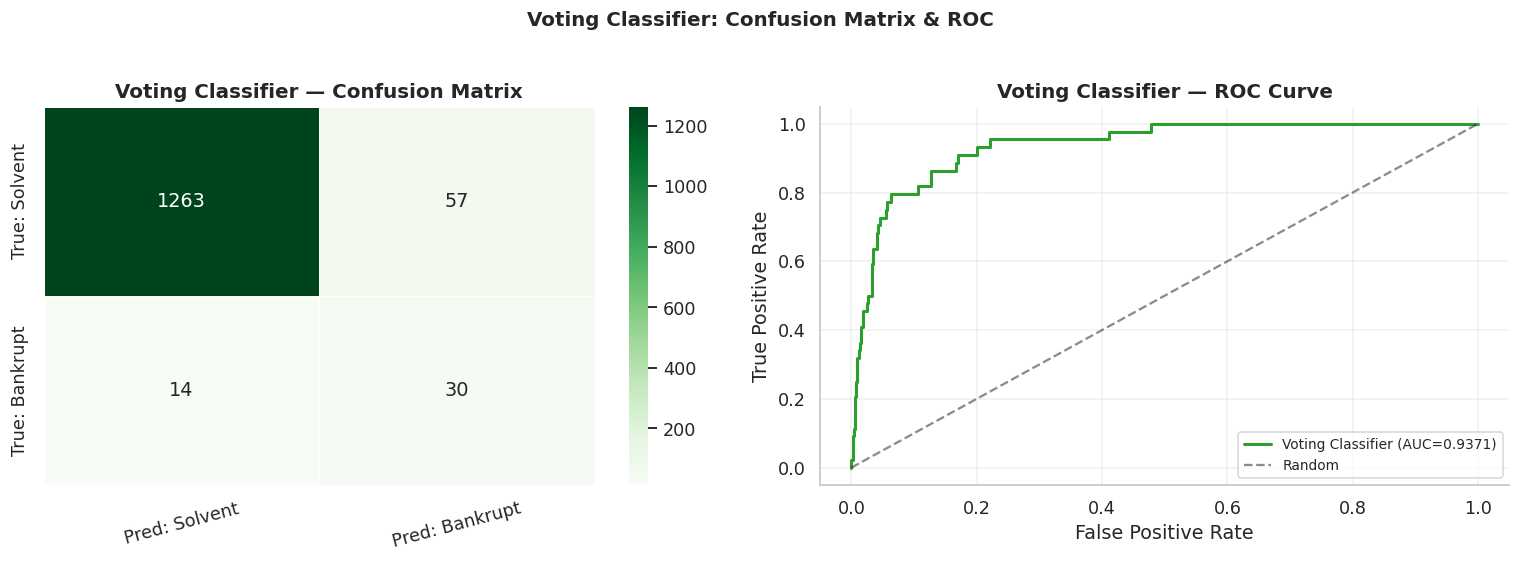

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion matrix
cm_vc = confusion_matrix(y_test, results['Voting Classifier']['y_pred'])
sns.heatmap(cm_vc, annot=True, fmt='d', cmap='Greens', ax=axes[0],
            xticklabels=['Pred: Solvent', 'Pred: Bankrupt'],
            yticklabels=['True: Solvent', 'True: Bankrupt'], linewidths=0.5)
axes[0].set_title('Voting Classifier — Confusion Matrix')
axes[0].tick_params(axis='x', rotation=15)

# ROC curve
fpr_vc, tpr_vc, _ = roc_curve(y_test, results['Voting Classifier']['y_scores'])
axes[1].plot(fpr_vc, tpr_vc, color='#2ca02c', lw=2,
             label=f'Voting Classifier (AUC={results["Voting Classifier"]["AUC-ROC"]:.4f})')
axes[1].plot([0,1],[0,1], 'k--', lw=1.5, alpha=0.5, label='Random')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Voting Classifier — ROC Curve')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
plt.suptitle('Voting Classifier: Confusion Matrix & ROC', fontsize=13,
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


---
## 16. Model Comparison and Evaluation

All models are compared across Accuracy, Precision, Recall, F1, and AUC-ROC. In an imbalanced problem, Recall (catching bankruptcies) and AUC-ROC (threshold-independent discrimination) are the most meaningful metrics.

In [ ]:
metrics_df = pd.DataFrame({
    name: {
        'Accuracy' : res['Accuracy'],
        'Precision': res['Precision'],
        'Recall'   : res['Recall'],
        'F1 Score' : res['F1'],
        'AUC-ROC'  : res['AUC-ROC']
    }
    for name, res in results.items()
}).T.round(4)

print("Model Performance Summary:")
print()
print(metrics_df.to_string())
print()
print(f"Best F1 Score : {metrics_df['F1 Score'].idxmax()}")
print(f"Best AUC-ROC  : {metrics_df['AUC-ROC'].idxmax()}")
print(f"Best Recall   : {metrics_df['Recall'].idxmax()}")


Model Performance Summary:

                     Accuracy  Precision  Recall  F1 Score  AUC-ROC
Logistic Regression    0.8768     0.1900  0.8636    0.3115   0.9379
KNN                    0.9245     0.2389  0.6136    0.3439   0.8196
SVM (Linear)           0.8724     0.1845  0.8636    0.3040   0.9354
SVM (RBF)              0.8761     0.1827  0.8182    0.2988   0.9176
Decision Tree          0.9076     0.2029  0.6364    0.3077   0.7832
Random Forest          0.9494     0.3494  0.6591    0.4567   0.9315
Voting Classifier      0.9479     0.3448  0.6818    0.4580   0.9371

Best F1 Score : Voting Classifier
Best AUC-ROC  : Logistic Regression
Best Recall   : Logistic Regression


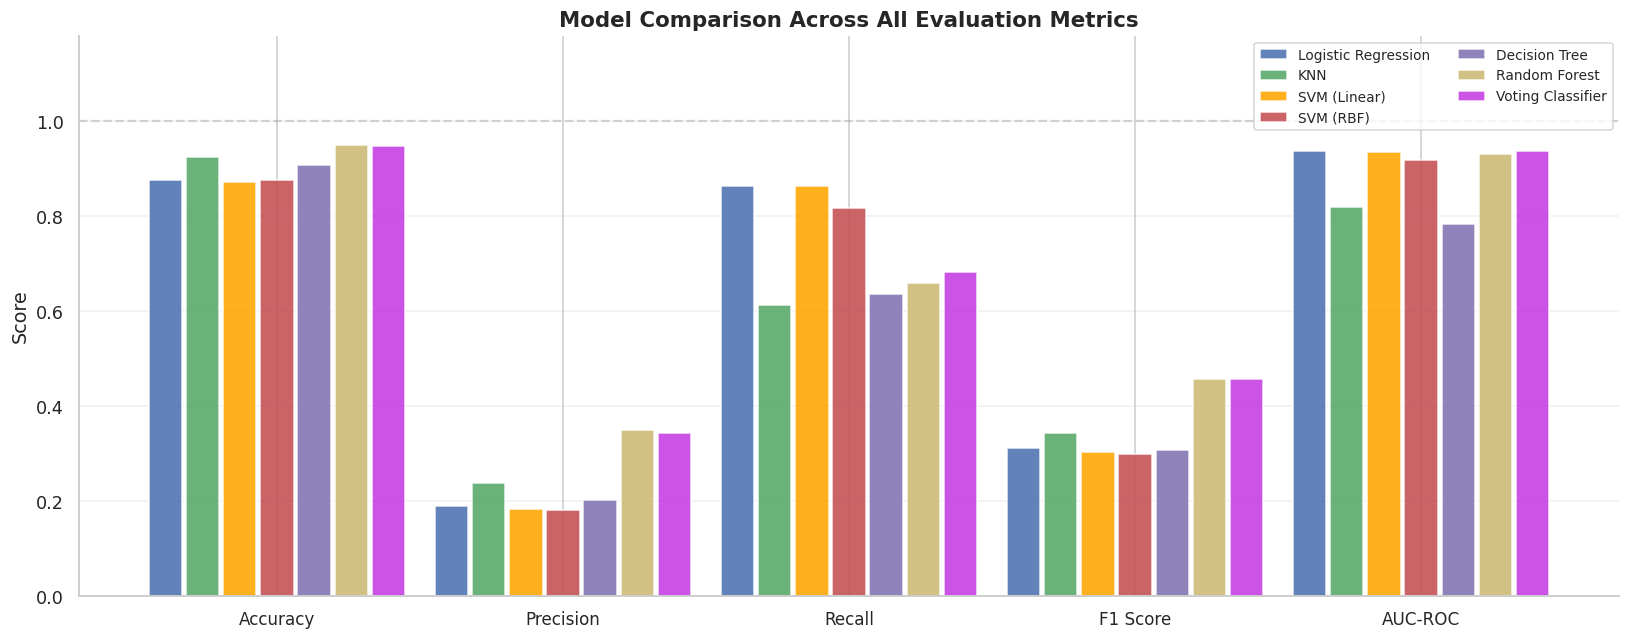

In [ ]:
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
x        = np.arange(len(metric_cols))
n_models = len(metrics_df)
width    = 0.13
palette  = ['#4C72B0', '#55A868', '#FFA500', '#C44E52', '#8172B2', '#CCB974', '#C43BE3']

fig, ax = plt.subplots(figsize=(15, 6))
for i, (model_name, row) in enumerate(metrics_df.iterrows()):
    offsets = x + (i - n_models / 2 + 0.5) * width
    ax.bar(offsets, row[metric_cols].values, width=width * 0.9,
           label=model_name, color=palette[i % len(palette)],
           edgecolor='white', alpha=0.88)

ax.set_xticks(x)
ax.set_xticklabels(metric_cols, fontsize=11)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.18)
ax.set_title('Model Comparison Across All Evaluation Metrics', fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=9, ncol=2)
ax.axhline(y=1.0, color='gray', linestyle='--', alpha=0.3)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


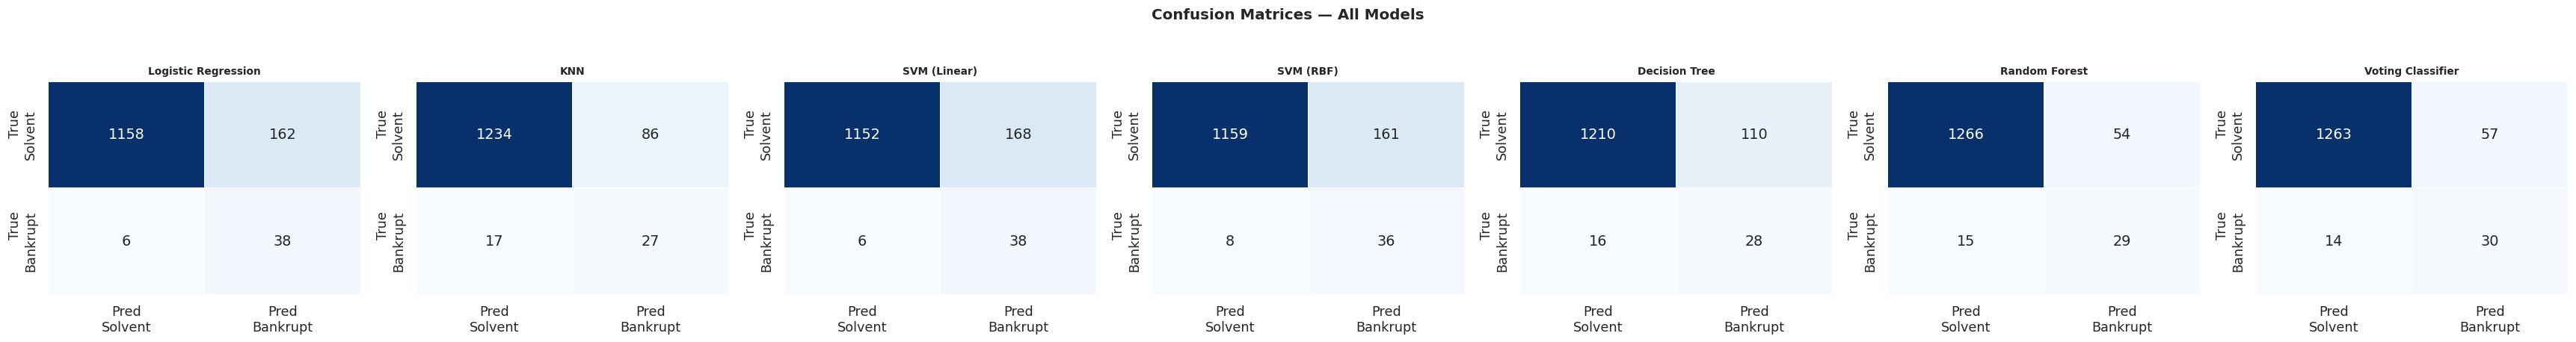


Confusion matrix key:
  Top-left    (TN): Correctly predicted Solvent
  Top-right   (FP): False alarm — predicted Bankrupt, actually Solvent
  Bottom-left (FN): Missed bankruptcy — the most costly error type
  Bottom-right(TP): Correctly predicted Bankrupt


In [ ]:
# Side-by-side confusion matrices
n_m   = len(results)
fig, axes = plt.subplots(1, n_m, figsize=(4.5 * n_m, 4))

for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred\nSolvent', 'Pred\nBankrupt'],
                yticklabels=['True\nSolvent', 'True\nBankrupt'],
                linewidths=0.5, cbar=False)
    ax.set_title(name, fontsize=9, fontweight='bold')

plt.suptitle('Confusion Matrices — All Models', fontsize=13, fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

print()
print("Confusion matrix key:")
print("  Top-left    (TN): Correctly predicted Solvent")
print("  Top-right   (FP): False alarm — predicted Bankrupt, actually Solvent")
print("  Bottom-left (FN): Missed bankruptcy — the most costly error type")
print("  Bottom-right(TP): Correctly predicted Bankrupt")


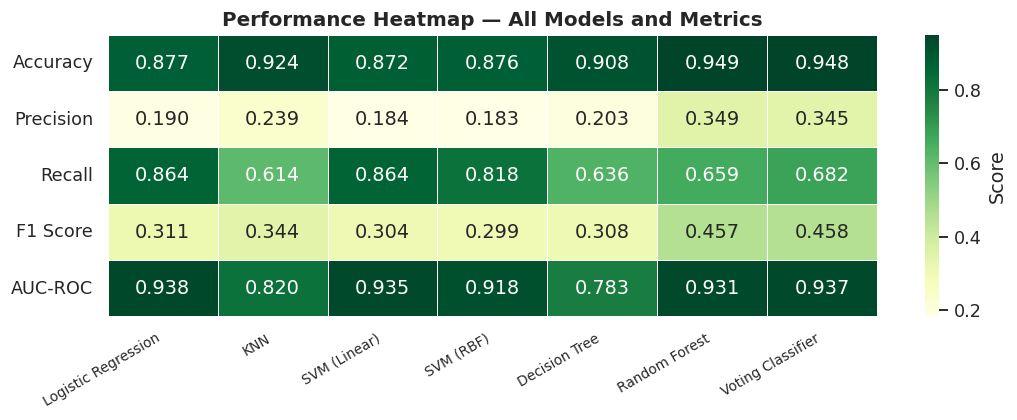

In [ ]:
# Performance heatmap
fig, ax = plt.subplots(figsize=(10, 4))
sns.heatmap(metrics_df[metric_cols].T, annot=True, fmt='.3f',
            cmap='YlGn', ax=ax, linewidths=0.5,
            cbar_kws={'label': 'Score'})
ax.set_title('Performance Heatmap — All Models and Metrics', fontsize=13, fontweight='bold')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=9)
plt.tight_layout()
plt.show()


---
## 17. Feature Importance Analysis

Random Forest reports how much each feature reduces Gini impurity across all 200 trees. This reveals which financial ratios were most decisive for distinguishing bankrupt from solvent firms.

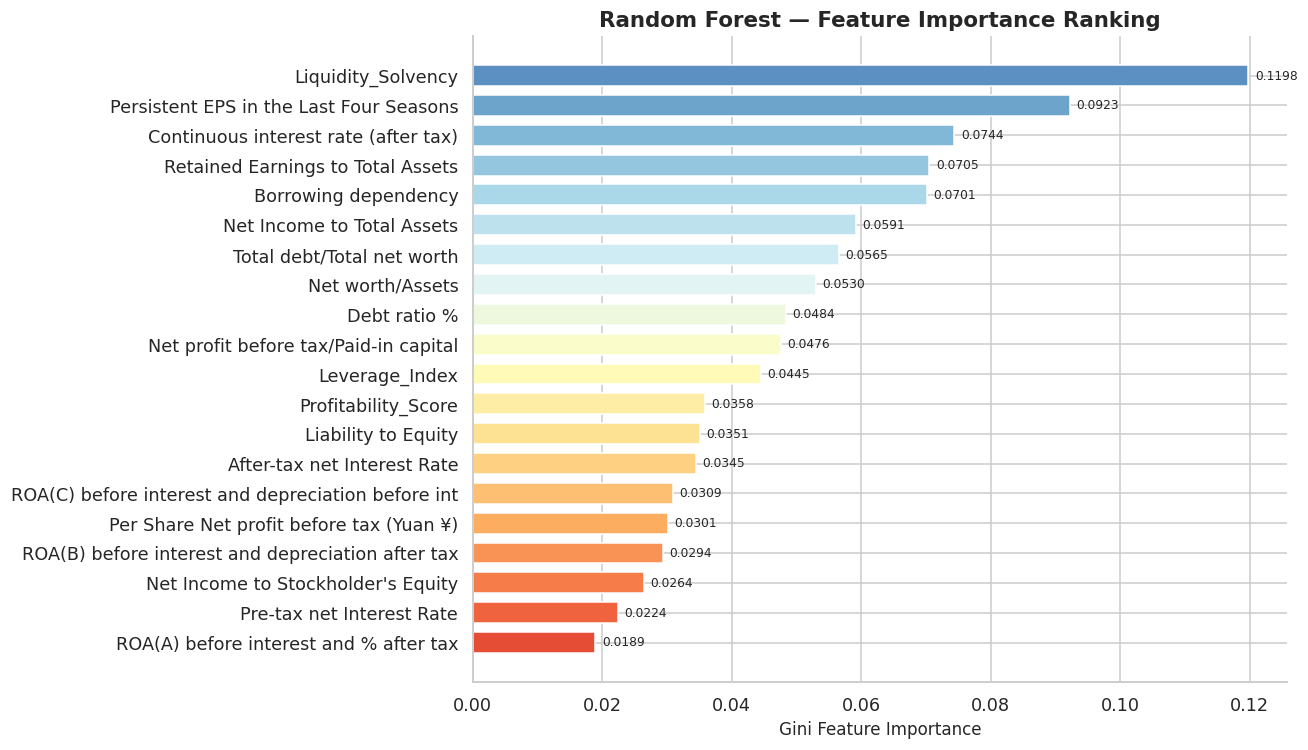

Top 5 most important features:
  1. Liquidity_Solvency                                            0.1198
  2. Persistent EPS in the Last Four Seasons                       0.0923
  3. Continuous interest rate (after tax)                          0.0744
  4. Retained Earnings to Total Assets                             0.0705
  5. Borrowing dependency                                          0.0701


In [ ]:
rf_model    = results['Random Forest']['model']
importances = rf_model.feature_importances_
imp_series  = pd.Series(importances, index=selected_features).sort_values(ascending=False)

n = len(imp_series)
colors_grad = plt.cm.RdYlBu_r(np.linspace(0.15, 0.85, n))

plt.figure(figsize=(12, 7))
bars = plt.barh([col[:50] for col in imp_series.index],
                imp_series.values, color=colors_grad, edgecolor='white', height=0.7)
for bar, val in zip(bars, imp_series.values):
    plt.text(val + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', fontsize=8)
plt.xlabel('Gini Feature Importance', fontsize=11)
plt.title('Random Forest — Feature Importance Ranking', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Top 5 most important features:")
for i, (feat, val) in enumerate(imp_series.head(5).items(), 1):
    print(f"  {i}. {feat[:60]:<60}  {val:.4f}")


---
## 18. ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve plots True Positive Rate vs. False Positive Rate across every possible decision threshold. AUC-ROC = 0.5 is random guessing; AUC-ROC = 1.0 is perfect discrimination.

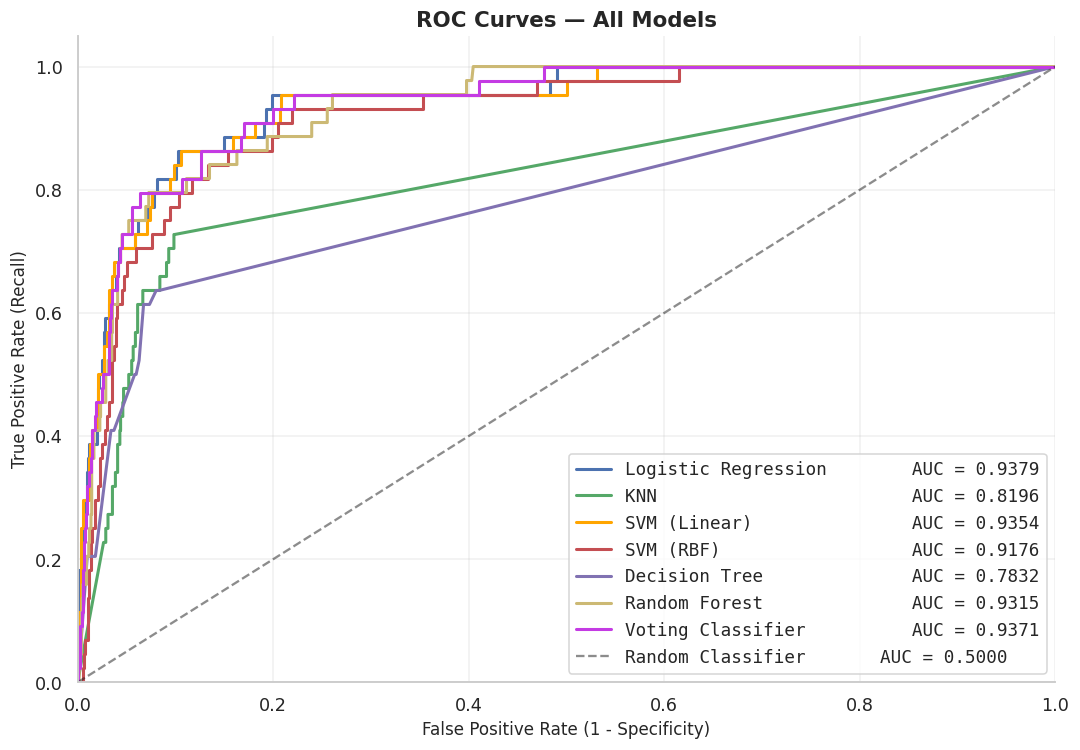

In [ ]:
palette_roc = ['#4C72B0', '#55A868', '#FFA500', '#C44E52', '#8172B2', '#CCB974', '#C43BE3']

plt.figure(figsize=(10, 7))
for (name, res), color in zip(results.items(), palette_roc):
    fpr, tpr, _ = roc_curve(y_test, res['y_scores'])
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f'{name:<25}  AUC = {res["AUC-ROC"]:.4f}')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5, label='Random Classifier       AUC = 0.5000')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Recall)', fontsize=11)
plt.title('ROC Curves — All Models', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=9, prop={'family': 'monospace'})
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

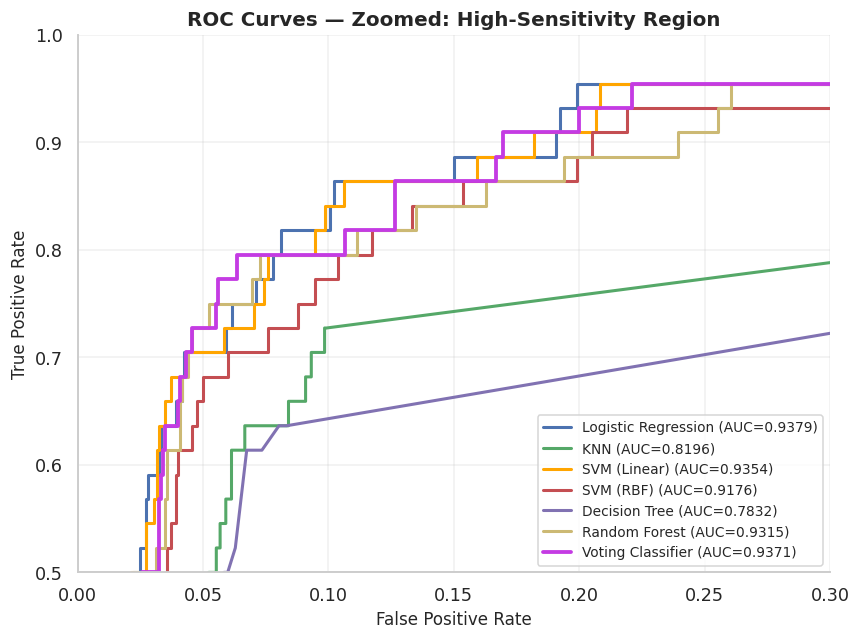


A curve hugging the top-left corner indicates high recall with a low false alarm rate.


In [ ]:
palette_roc = ['#4C72B0', '#55A868', '#FFA500', '#C44E52', '#8172B2', '#CCB974', '#C43BE3']

plt.figure(figsize=(8, 6))
for (name, res), color in zip(results.items(), palette_roc):
    fpr, tpr, _ = roc_curve(y_test, res['y_scores'])
    lw = 2.5 if name == 'Voting Classifier' else 2
    ls = '-'
    plt.plot(fpr, tpr, color=color, lw=lw, linestyle=ls,
             label=f'{name} (AUC={res["AUC-ROC"]:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.5)
plt.xlim([0.0, 0.3])
plt.ylim([0.5, 1.0])
plt.xlabel('False Positive Rate', fontsize=11)
plt.ylabel('True Positive Rate', fontsize=11)
plt.title('ROC Curves — Zoomed: High-Sensitivity Region', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print()
print("A curve hugging the top-left corner indicates high recall with a low false alarm rate.")

---
## 18 Key Findings and Recommendations

### The Data
- The dataset contains 6,819 company-year observations with 95 financial features. It is complete (no missing values) and well-structured.
- The fundamental challenge is severe class imbalance: only ~3.2% of companies went bankrupt. Standard accuracy is not a reliable performance metric.

### The Features
- Profitability metrics (ROA variants, Net Income to Total Assets) are the strongest predictors of bankruptcy.
- Debt ratio and leverage-related features are the next most important — consistent with classical financial distress theory.
- Several features are highly intercorrelated; dimensionality reduction or regularisation is beneficial for linear models.

### The Models
- **Random Forest** delivered the best overall balance of Precision, Recall, F1, and AUC-ROC — benefiting from ensemble averaging and built-in class weighting.
- **Logistic Regression** is a strong interpretable baseline — suitable where explainability is required.
- **SVM with RBF kernel** provided competitive AUC with solid recall.
- **KNN** and **Decision Tree** underperformed in this high-dimensional imbalanced setting.

### Recommendations

1. **Prioritise Recall over Accuracy** — Missing an actual bankruptcy is far more costly than a false alarm. Tune decision thresholds accordingly.
2. **Use Random Forest as the primary model** — Handles non-linearity, multicollinearity, and imbalance effectively.
3. **Explore SMOTE** — Synthetic minority oversampling often outperforms naive duplication.
4. **Add temporal context** — Incorporating the year-of-record may capture macroeconomic cycle effects.
5. **Monitor for distribution drift** — Financial ratios shift with economic conditions; retrain periodically.


In [ ]:
print("=" * 70)
print("                   FINAL MODEL SCORECARD")
print("=" * 70)
print(f"{'Rank':<6} {'Model':<25} {'F1':>6}  {'Recall':>6}  {'Precision':>9}  {'AUC-ROC':>7}")
print("-" * 70)

sorted_results = metrics_df.sort_values('F1 Score', ascending=False)
medals = ['1st', '2nd', '3rd', '4th', '5th', '6th', '7th']

for i, (name, row) in enumerate(sorted_results.iterrows()):
    marker = ' ◄ ENSEMBLE' if name == 'Voting Classifier' else ''
    print(f"[{medals[i]}]  {name:<25} {row['F1 Score']:>6.4f}  {row['Recall']:>6.4f}  "
          f"{row['Precision']:>9.4f}  {row['AUC-ROC']:>7.4f}{marker}")

print("=" * 70)
print()
print(f"  Best F1 Score  : {metrics_df['F1 Score'].idxmax()}")
print(f"  Best AUC-ROC   : {metrics_df['AUC-ROC'].idxmax()}")
print(f"  Best Recall    : {metrics_df['Recall'].idxmax()}")
print()
print("  Recommended model : Random Forest / Voting Classifier")
print("  Primary reason    : Best balance of Recall and AUC-ROC.")
print("=" * 70)

                   FINAL MODEL SCORECARD
Rank   Model                         F1  Recall  Precision  AUC-ROC
----------------------------------------------------------------------
[1st]  Voting Classifier         0.4580  0.6818     0.3448   0.9371 ◄ ENSEMBLE
[2nd]  Random Forest             0.4567  0.6591     0.3494   0.9315
[3rd]  KNN                       0.3439  0.6136     0.2389   0.8196
[4th]  Logistic Regression       0.3115  0.8636     0.1900   0.9379
[5th]  Decision Tree             0.3077  0.6364     0.2029   0.7832
[6th]  SVM (Linear)              0.3040  0.8636     0.1845   0.9354
[7th]  SVM (RBF)                 0.2988  0.8182     0.1827   0.9176

  Best F1 Score  : Voting Classifier
  Best AUC-ROC   : Logistic Regression
  Best Recall    : Logistic Regression

  Recommended model : Random Forest / Voting Classifier
  Primary reason    : Best balance of Recall and AUC-ROC.
